<a href="https://colab.research.google.com/github/KhushiShrivastav06/AI-Lab/blob/main/Week9_ResolutionFOL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

How many clauses are in your Knowledge Base? 5
Enter KB clause #1 (use '|' for OR, '~' for negation):  ~Science(x) | Physics(x) | Math(x)
Enter KB clause #2 (use '|' for OR, '~' for negation): ~Math(x) | Stats(x)
Enter KB clause #3 (use '|' for OR, '~' for negation): Science(Alice)
Enter KB clause #4 (use '|' for OR, '~' for negation): Physics(Bob)
Enter KB clause #5 (use '|' for OR, '~' for negation): ~Stats(x) | Data(x)
Enter your Negated Goal clause (e.g., ~Likes(John, Peanuts)): Data(Alice)
The negated goal 'Data(Alice)' is NOT false (Could not resolve to contradiction; original goal cannot be proved).


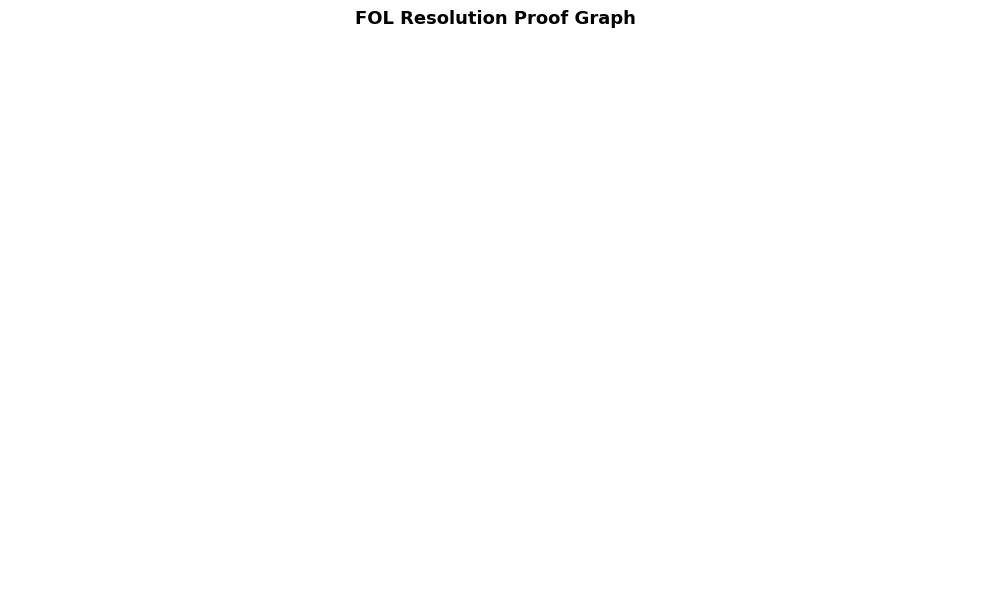

In [5]:
from itertools import combinations
import matplotlib.pyplot as plt
import networkx as nx


def is_variable(term):
    """Lowercase identifiers (e.g., 'x', 'y') are variables; capitalized are constants."""
    return isinstance(term, str) and len(term) > 0 and term[0].islower()


def parse_term(term_str):
    term_str = term_str.strip()
    if "(" in term_str and term_str.endswith(")"):
        func, args = term_str[:-1].split("(", 1)
        return (func.strip(), tuple(parse_term(a) for a in args.split(",")))
    return term_str


def format_term(term):
    if isinstance(term, tuple):
        return f"{term[0]}({', '.join(format_term(a) for a in term[1])})"
    return str(term)


def parse_literal(lit_str):
    lit_str = lit_str.strip()
    negated = lit_str.startswith("~")
    if negated:
        lit_str = lit_str[1:].strip()
    pred, args = lit_str[:-1].split("(", 1)
    parsed_args = tuple(parse_term(a) for a in args.split(","))
    return (negated, pred.strip(), parsed_args)


def format_literal(lit):
    negated, pred, args = lit
    prefix = "~" if negated else ""
    return f"{prefix}{pred}({', '.join(format_term(a) for a in args)})"


def parse_clause(clause_str):
    return canonicalize_clause(
        frozenset(parse_literal(part) for part in clause_str.split("|"))
    )


def format_clause(clause):
    if not clause:
        return "FALSE (Contradiction)"
    return " | ".join(sorted(format_literal(lit) for lit in clause))


def canonicalize_clause(clause):
    """Normalizes variable names (v0, v1, ...) so equivalent clauses match in sets."""
    mapping = {}

    def rename(term):
        if is_variable(term):
            if term not in mapping:
                mapping[term] = f"v{len(mapping)}"
            return mapping[term]
        if isinstance(term, tuple):
            return (term[0], tuple(rename(a) for a in term[1]))
        return term

    # Sort literals first so variable numbering is deterministic
    sorted_lits = sorted(clause, key=lambda l: (l[1], l[0], str(l[2])))
    return frozenset(
        (neg, pred, tuple(rename(a) for a in args)) for neg, pred, args in sorted_lits
    )


def occurs_check(var, term, theta):
    if var == term:
        return True
    if is_variable(term) and term in theta:
        return occurs_check(var, theta[term], theta)
    if isinstance(term, tuple):
        return any(occurs_check(var, arg, theta) for arg in term[1])
    return False


def unify(x, y, theta=None):
    if theta is None:
        theta = {}
    if x == y:
        return theta
    if is_variable(x):
        return unify_var(x, y, theta)
    if is_variable(y):
        return unify_var(y, x, theta)
    if isinstance(x, tuple) and isinstance(y, tuple) and len(x) == len(y):
        for a, b in zip(x, y):
            theta = unify(a, b, theta)
            if theta is None:
                return None
        return theta
    return None


def unify_var(var, val, theta):
    if var in theta:
        return unify(theta[var], val, theta)
    if is_variable(val) and val in theta:
        return unify(var, theta[val], theta)
    if occurs_check(var, val, theta):
        return None
    new_theta = dict(theta)
    new_theta[var] = val
    return new_theta


def apply_substitution(term, theta):
    if is_variable(term):
        while is_variable(term) and term in theta:
            term = theta[term]
        if isinstance(term, tuple):
            return apply_substitution(term, theta)
        return term
    if isinstance(term, tuple):
        return (term[0], tuple(apply_substitution(a, theta) for a in term[1]))
    return term


def substitute_literal(lit, theta):
    negated, pred, args = lit
    return (negated, pred, tuple(apply_substitution(a, theta) for a in args))


def standardize_apart(clause, prefix):
    mapping = {}

    def rename(term):
        if is_variable(term):
            if term not in mapping:
                mapping[term] = f"{prefix}_{term}"
            return mapping[term]
        if isinstance(term, tuple):
            return (term[0], tuple(rename(a) for a in term[1]))
        return term

    return frozenset(
        (neg, pred, tuple(rename(a) for a in args)) for neg, pred, args in clause
    )


def resolve(ci, cj):
    ci_std = standardize_apart(ci, "a")
    cj_std = standardize_apart(cj, "b")
    resolvents = set()

    for lit_i in ci_std:
        for lit_j in cj_std:
            if lit_i[1] == lit_j[1] and lit_i[0] != lit_j[0]:
                theta = unify(lit_i[2], lit_j[2], {})
                if theta is not None:
                    new_literals = (ci_std - {lit_i}) | (cj_std - {lit_j})
                    resolvent = canonicalize_clause(
                        frozenset(substitute_literal(lit, theta) for lit in new_literals)
                    )
                    resolvents.add(resolvent)
    return resolvents


def fol_resolution_with_proof(kb_clauses, negated_goal, max_iterations=50):
    clauses = list(dict.fromkeys(kb_clauses + [negated_goal]))
    clause_set = set(clauses)
    frontier = list(clauses)
    parents = {}

    for _ in range(max_iterations):
        new_resolvents = []

        # Only resolve pairs involving at least one newly derived clause
        pairs = [(ci, cj) for ci in frontier for cj in clauses if ci != cj]
        for ci, cj in pairs:
            for resolvent in resolve(ci, cj):
                if resolvent not in clause_set:
                    clause_set.add(resolvent)
                    new_resolvents.append(resolvent)
                    parents[resolvent] = (ci, cj)

                if not resolvent:
                    return True, parents

        if not new_resolvents:
            return False, parents

        clauses.extend(new_resolvents)
        frontier = new_resolvents

    return False, parents


def plot_proof_graph(proved, parents):
    plt.figure(figsize=(10, 6))
    plt.title("FOL Resolution Proof Graph", fontsize=13, fontweight="bold")

    if not proved:
        plt.axis("off")
        plt.tight_layout()
        plt.show()
        return

    graph = nx.DiGraph()
    stack = [frozenset()]
    visited = set()

    while stack:
        curr = stack.pop()
        if curr in visited:
            continue
        visited.add(curr)
        curr_label = format_clause(curr)
        graph.add_node(curr_label)

        if curr in parents:
            p1, p2 = parents[curr]
            graph.add_edge(format_clause(p1), curr_label)
            graph.add_edge(format_clause(p2), curr_label)
            stack.extend([p1, p2])

    pos = nx.spring_layout(graph, seed=42, k=1.5)
    node_colors = [
        "#ff9999" if node == "FALSE (Contradiction)" else "#cce5ff"
        for node in graph.nodes()
    ]

    nx.draw(
        graph,
        pos,
        with_labels=True,
        node_color=node_colors,
        node_size=3200,
        font_size=9,
        font_weight="bold",
        edge_color="#555555",
        arrows=True,
        arrowsize=18,
    )
    plt.axis("off")
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    n = int(input("How many clauses are in your Knowledge Base? "))
    kb = []
    for i in range(1, n + 1):
        raw_clause = input(f"Enter KB clause #{i} (use '|' for OR, '~' for negation): ")
        kb.append(parse_clause(raw_clause))

    neg_goal_str = input("Enter your Negated Goal clause (e.g., ~Likes(John, Peanuts)): ")
    neg_goal = parse_clause(neg_goal_str)

    proved, parents = fol_resolution_with_proof(kb, neg_goal)

    if proved:
        print(
            f"The negated goal '{neg_goal_str}' is FALSE "
            "(Contradiction reached; original goal is PROVED!)."
        )
    else:
        print(
            f"The negated goal '{neg_goal_str}' is NOT false "
            "(Could not resolve to contradiction; original goal cannot be proved)."
        )

    plot_proof_graph(proved, parents)
